# Week 5 — Omnichannel Optimization and Next Best Action: from a touch log to a decision engine
## Case: GLUCOREN, H1 2026 — 6,000 targeted HCPs, 26 weeks, 156,000 HCP-weeks, one randomized exploration arm

**Applied Data Science and AI in Pharma Commercial · Columbia DSI · Fall 2026 · Monday, October 12**

Week 4 answered the Marketing Director's *who* question with five behavioral segments and an activation matrix. Tonight the Omnichannel Lead asks the question that comes right after it — and asks it every week:

> *"For each of these 6,000 prescribers, this week: a rep call, an approved email, a digital placement, or nothing? And how will we know it worked without waiting a year?"*

That is **Next Best Action (NBA)**. An NBA engine is three components in sequence: **segmentation / micro-segmentation** (Week 4 — who the HCP is), **affinity prediction** (§4 — which channels reach them), and the **NBA layer** (§5–8 — which action pays, under the rules). It is the industry's own term (Veeva CRM Suggestions, 2015: "data-driven recommendations on next best action and channel"; IQVIA's NBA engine, 2025: "touchpoints are coordinated across channels and teams"; McKinsey: "an optimized sequence of interactions for each HCP or segment"). The vocabulary tonight is the industry's throughout — the Field Guide (Part 11) maps every term to its IQVIA / ZS / Axtria / McKinsey / EY / Komodo / Veeva source; the two exceptions (contextual bandit, offline policy evaluation) come from the online-advertising literature and are labelled as such. The structure of the night is the structure of a real NBA build:

1. **The data** — an HCP-week touch log with the action taken, the context at the time, and the outcome; 25% of HCP-weeks randomized (the exploration arm).
2. **The response-model trap** — the model everyone builds first, and why it recommends calling the people who would have prescribed anyway.
3. **HCP affinity prediction** — affinity is observed for a subset of HCPs and channels; collaborative filtering fills the matrix, with the Week 4 micro-segments as the cold-start prior.
4. **Uplift modeling** — T-learner, X-learner (and a causal forest, optional) on the exploration arm; Qini curves; grading against the planted truth.
5. **Saturation, frequency caps, and channel substitution** — the marginal value of the *n*th touch (IQVIA has documented "overkill and saturation" and "digital fatigue" in its channel research), and the business rules that fall out of it.
6. **The NBA scoring layer** — expected incremental value per action, suppression rules, argmax. Compared with the legacy rules engine.
7. **Offline policy evaluation** — IPS, SNIPS, doubly robust: how to score a policy that was never run, from a log that was.
8. **A toy contextual bandit** — ε-greedy vs. Thompson sampling vs. the legacy engine, on a simulator built from what we learned.
9. **Patient predictive modeling** — a discontinuation-risk model on the Week 4 patient file, and the patient-side NBA it triggers; governance.
10. **Orchestration** — triggers, suppression rules, the CDP, and the measurement plan.

The data is **synthetic** and generated from planted mechanisms, which is the only reason the grading cells are possible. No real prescriber, patient, or brand is represented.

| file | grain | what it represents |
|---|---|---|
| `glucoren_touch_log.csv` | one row per HCP × week (6,000 × 26) | arm (legacy / explore), action taken, the logging propensity, the context at decision time (touches in the trailing 4 weeks by channel, weeks since last call, last action, trailing weekly NBRx), an engagement flag, a complaint flag, and the outcome (GLUCOREN NBRx in the following 2 weeks) |
| `glucoren_hcp_segments.csv` | one row per HCP | the Week 4 segmentation as delivered (segment, growth group), decile, baseline weekly NBRx (H2 2025), email consent, pharmacy-reject rate |
| `glucoren_hcp_master.csv` | one row per HCP | the Week 4 master file (specialty, region, setting, patient mix) |
| `glucoren_patients.csv` | one row per patient (20,000) | the Week 4 patient extract, used in §9 |
| `_INSTRUCTOR_touch_log_truth.csv`, `_INSTRUCTOR_hcp_true_uplift.csv`, `_INSTRUCTOR_affinity_truth.csv`, `_INSTRUCTOR_nba_truth.json` | — | the full affinity matrix, the planted uplift of every action for every HCP-week (and per HCP in a fresh state), and the generating parameters (in the instructor folder; grading cells print a notice and skip if absent) |

**Why the exploration arm matters.** In industry language this is a test-and-control design — ZS calls test and control "the backbone of success measurement"; in bandit language it is the exploration arm. In the 75% of HCP-weeks run by the legacy rules engine, *who got a call* was decided by decile — the same thing that decides who writes a lot. Any model fit to those rows learns the targeting rule, not the effect of the call. The 25% randomized rows are the only place the effect of an action can be read directly. This is Week 3's geo-lift test at the HCP-week grain, and it is the single most important design decision in an NBA program.


## 1. Setup

In [1]:
import json, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import HistGradientBoostingRegressor as HGBR, HistGradientBoostingClassifier as HGBC
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.calibration import calibration_curve
import statsmodels.api as sm, statsmodels.formula.api as smf
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
NAVY, CORAL, ICE, TEAL, GOLD, GREY, VIOLET = "#1E2761", "#FF6B6B", "#CADCFC", "#2A9D8F", "#E8B04B", "#8A8A8A", "#7B61FF"
ACT_COLORS = {"none": GREY, "call": NAVY, "email": CORAL, "digital": TEAL}
SEG_ORDER = ["Core", "Movers", "Access-constrained", "Entrenched", "Long tail"]
RNG = 20261012

# The package keeps data in ./data and instructor files in the instructor folder; a flat folder also works.
DATA = next((p for p in [Path("data"), Path(".")] if (p / "glucoren_touch_log.csv").exists()), Path("."))
INSTR = next((p for p in [Path("instructor material"), Path("../Instructor material/instructor material_w5"), Path("data"), Path(".")] if (p / "_INSTRUCTOR_touch_log_truth.csv").exists()), Path("instructor material"))
IMG = next((p for p in [Path("instructor material/build/img"), Path("../Instructor material/instructor material_w5/build/img")] if p.exists()), Path("instructor material/build/img"))
def show(name=None):
    plt.tight_layout()
    if name and IMG.exists(): plt.savefig(IMG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

log = pd.read_csv(DATA / "glucoren_touch_log.csv")
segs = pd.read_csv(DATA / "glucoren_hcp_segments.csv")
master = pd.read_csv(DATA / "glucoren_hcp_master.csv")
patients = pd.read_csv(DATA / "glucoren_patients.csv")
log = log.merge(segs, on="hcp_id").merge(master[["hcp_id", "specialty", "region", "practice_setting"]], on="hcp_id")
log["touches_4w"] = log.calls_4w + log.emails_4w + log.digital_4w
WEEKS = sorted(log.week.unique())
VALUE_PER_NBRX, COST = 1200.0, {"none": 0.0, "call": 180.0, "email": 2.0, "digital": 6.0}   # planning conventions (see Field Guide Part 5)
print("HCP-weeks:", log.shape[0], "| HCPs:", log.hcp_id.nunique(), "| weeks:", WEEKS[0], "→", WEEKS[-1])
print("arm mix:", log.arm.value_counts(normalize=True).round(3).to_dict())
log.head(3)

HCP-weeks: 156000 | HCPs: 6000 | weeks: 2026-01-05 → 2026-06-29
arm mix: {'legacy': 0.749, 'explore': 0.251}


,hcp_id,week,arm,action,propensity,calls_4w,emails_4w,digital_4w,weeks_since_call,last_action,trailing_nbrx_wk,engaged,complaint,nbrx_2w,segment,growth_group,decile,baseline_nbrx_wk,email_consent,glucoren_reject_rate,specialty,region,practice_setting,touches_4w
0,H100000,2026-01-05,explore,call,0.250,0,0,0,99,none,0.606,0,0,1,Movers,Champions,6,0.606,1,0.087,PCP,Northeast,Group practice,0
1,H100001,2026-01-05,legacy,none,0.580,0,0,0,99,none,0.387,0,0,1,Movers,Champions,6,0.387,1,0.082,PCP,West,Health system / IDN,0
2,H100002,2026-01-05,explore,email,0.250,0,0,0,99,none,0.389,0,0,1,Entrenched,Stable,10,0.389,0,0.008,Endocrinology,Northeast,Independent practice,0


## 2. The data — what a touch log is, and what the legacy engine did with it
Three things to see before any model:
1. **One action per HCP-week.** `none` is an action too — it is the one the NBA engine will most often be right to pick.
2. **The legacy engine targets volume.** Calls go to deciles 9–10; emails go to anyone with consent; digital runs on a rotation. The context columns (`calls_4w`, …) are what the engine *did*, not what the HCP *wanted*.
3. **The exploration arm is uniform.** 25% of HCP-weeks, each of the four actions with probability 0.25, regardless of who the HCP is. The `propensity` column holds the logging probability for every row — the legacy engine's rules were written down as probabilities, which is what makes §7 possible.

action   none  call  email  digital
arm                                
explore 0.254 0.249  0.249    0.247
legacy  0.574 0.159  0.167    0.100


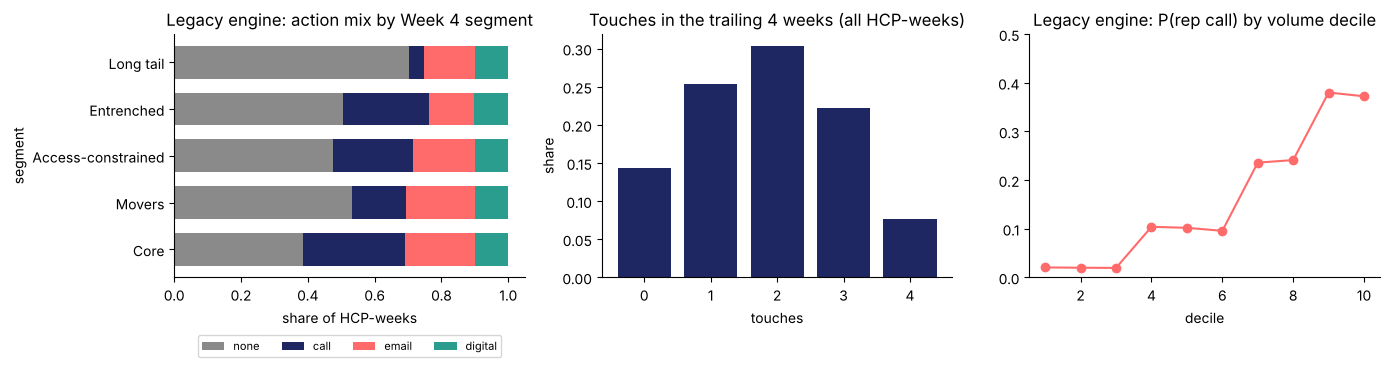

mean touches per HCP per 4 weeks: 1.83 | HCP-weeks with ≥4 touches in the trailing 4 weeks: 7.7%
emails sent without consent: 2450 | complaints logged: 135


In [2]:
mix = log.groupby(["arm", "action"]).size().unstack().reindex(columns=["none", "call", "email", "digital"])
print((mix.T / mix.sum(1)).T.round(3))
by_seg = log[log.arm == "legacy"].groupby(["segment", "action"]).size().unstack().reindex(SEG_ORDER)[["none", "call", "email", "digital"]]
by_seg = (by_seg.T / by_seg.sum(1)).T
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
by_seg.plot(kind="barh", stacked=True, ax=ax[0], color=[ACT_COLORS[a] for a in by_seg.columns], width=0.7); ax[0].set_title("Legacy engine: action mix by Week 4 segment"); ax[0].set_xlabel("share of HCP-weeks"); ax[0].legend(ncol=4, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, -0.35))
t4 = log.touches_4w.value_counts(normalize=True).sort_index()
ax[1].bar(t4.index, t4.values, color=NAVY); ax[1].set_title("Touches in the trailing 4 weeks (all HCP-weeks)"); ax[1].set_xlabel("touches"); ax[1].set_ylabel("share")
cp = log[log.arm == "legacy"].groupby("decile").apply(lambda d: (d.action == "call").mean())
ax[2].plot(cp.index, cp.values, "o-", color=CORAL); ax[2].set_title("Legacy engine: P(rep call) by volume decile"); ax[2].set_xlabel("decile"); ax[2].set_ylim(0, 0.5)
show("data")
print("mean touches per HCP per 4 weeks:", round(log.touches_4w.mean(), 2), "| HCP-weeks with ≥4 touches in the trailing 4 weeks:", f"{(log.touches_4w >= 4).mean():.1%}")
print("emails sent without consent:", int(((log.action == 'email') & (log.email_consent == 0)).sum()), "| complaints logged:", int(log.complaint.sum()))

## 3. The response-model trap
The model family is what the industry calls **promotion response modeling** (Axtria): the impact of promotional activity on prescribing. The first version every brand builds: *predict NBRx after a call, call the HCPs with the highest predicted NBRx.* It is a good model of the wrong quantity. Below, (a) the naive comparison on the legacy arm — called vs. not called — and (b) the same comparison on the exploration arm, where the call was a coin flip.

**Vocabulary (keep it for the rest of the course).** *Response* = what happens after the action. *Uplift* (incremental effect, CATE) = what happens after the action **minus** what would have happened anyway. Four kinds of HCP (Radcliffe & Surry, 2011 — the originating uplift-modelling source): **sure things** (prescribe either way), **persuadables** (prescribe only if touched), **lost causes** (never), **sleeping dogs** (touching them hurts). A response model ranks sure things first. Only the persuadables are worth money.

LEGACY arm (targeted by decile) — naive 'responders vs non-responders':
         mean   size  vs none
action                       
none    0.891  67024    0.000
call    1.952  18603    1.061
email   1.405  19530    0.514
digital 1.167  11663    0.276

EXPLORE arm (randomized) — honest average effect per action:
         mean  size  vs none
action                      
none    1.112  9953    0.000
call    1.213  9766    0.100
email   1.217  9766    0.104
digital 1.205  9695    0.093


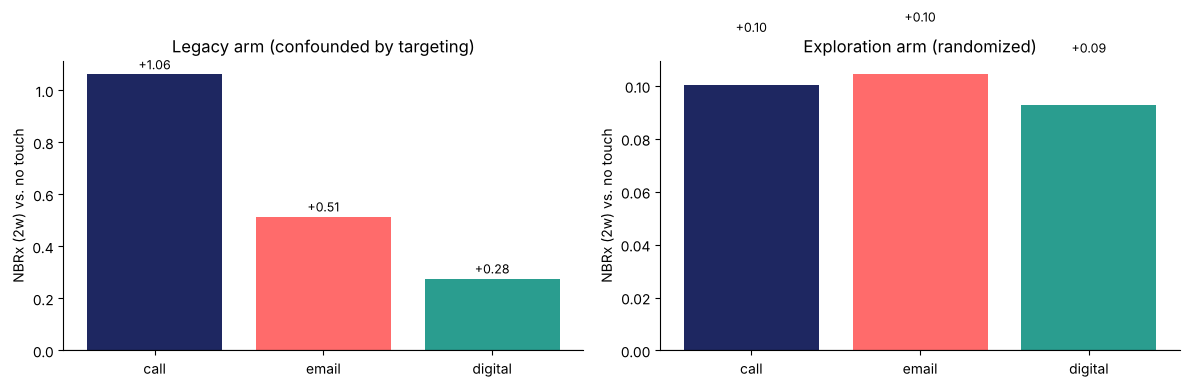


Who the response model puts in its top decile:
segment
Core                 0.623
Movers               0.300
Access-constrained   0.076
Entrenched           0.000
Long tail            0.001
Name: proportion, dtype: float64


In [3]:
def diff_table(d):
    g = d.groupby("action").nbrx_2w.agg(["mean", "size"])
    g["vs none"] = g["mean"] - g.loc["none", "mean"]
    return g.reindex(["none", "call", "email", "digital"])
naive = diff_table(log[log.arm == "legacy"]); honest = diff_table(log[log.arm == "explore"])
print("LEGACY arm (targeted by decile) — naive 'responders vs non-responders':"); print(naive.round(3))
print("\nEXPLORE arm (randomized) — honest average effect per action:"); print(honest.round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a_, (t, name) in zip(ax, [(naive, "Legacy arm (confounded by targeting)"), (honest, "Exploration arm (randomized)")]):
    v = t["vs none"].drop("none"); a_.bar(v.index, v.values, color=[ACT_COLORS[x] for x in v.index]); a_.axhline(0, color="k", lw=0.8)
    a_.set_title(name); a_.set_ylabel("NBRx (2w) vs. no touch")
    for i, y in enumerate(v.values): a_.text(i, y + (0.02 if y >= 0 else -0.06), f"{y:+.2f}", ha="center", fontsize=9)
show("naive_vs_rct")
# the response model: predict NBRx from context (no action), rank; who does it tell you to call?
X_resp = pd.get_dummies(log[["decile", "trailing_nbrx_wk", "touches_4w", "weeks_since_call", "email_consent", "glucoren_reject_rate", "segment", "specialty"]], drop_first=True)
resp = HGBR(max_iter=200, learning_rate=0.08, random_state=RNG).fit(X_resp[log.arm == "legacy"], log.nbrx_2w[log.arm == "legacy"])
log["resp_score"] = resp.predict(X_resp)
top = log[log.resp_score >= log.resp_score.quantile(0.9)]
print("\nWho the response model puts in its top decile:"); print(top.segment.value_counts(normalize=True).reindex(SEG_ORDER).round(3))

**What just happened.** On the legacy arm, called HCP-weeks show far more NBRx than un-called ones — because calls went to deciles 9–10. On the randomized arm the honest effect of a call is a fraction of that. And the response model's top decile is almost entirely the Core segment: HCPs who prescribe GLUCOREN heavily whether or not anyone calls. That is the trap. The fix is not a better response model; it is a different target — the *difference* — and that needs either randomization or a credible causal design.

## 4. HCP affinity prediction — filling in a matrix you only partly observe
The industry's word is **channel preference / affinity**: which channels an HCP engages with. IQVIA's NBA engine builds on a "360-degree view of HCP preferences"; its Channel Dynamics research measures stated preference by survey. The practical problem: the brand *knows* the affinity of a subset — HCPs with enough history on a channel, plus a few hundred surveyed HCPs — and needs it for all 6,000, on channels most of them have never been offered.

That is a **recommender-system** problem: a sparse HCP × channel matrix, fill in the blanks. The standard tool is **collaborative filtering** — HCPs who engage alike on the channels we have seen will engage alike on the ones we have not — with the Week 4 segmentation as the prior for HCPs we have never seen at all (cold start).

| file | grain | what it holds |
|---|---|---|
| `glucoren_hcp_channel_affinity.csv` | one row per observed HCP × channel | affinity = engagement rate (0–1) on six channels: rep call, approved email, webinar, digital banner, conference, remote call; `source` = history or survey |

Four estimators, from naive to standard:
1. **Segment × channel mean** — Week 4's micro-segments as the prior. No individual signal.
2. **k-nearest neighbours on Week 4 features** (content-based) — HCPs who *look* alike.
3. **Matrix factorization** (ALS with biases) — HCPs who *behave* alike on the channels we have seen. This is collaborative filtering.
4. **Hybrid** — matrix factorization where the HCP has history; the segment prior where it has none.

Evaluation: hold out 20% of observed cells, and *all* cells of 10% of HCPs (cold start). The instructor file has the full matrix, so we also grade on the cells nobody observed.

observed cells: 44.4% of 36,000 | HCPs with no observed channel: 404 | survey HCPs: 600
                          rep_call  approved_email  webinar  digital_banner  conference  remote_call
coverage                     0.687           0.626    0.313           0.518       0.273        0.248
mean affinity (observed)     0.356           0.203    0.335           0.271       0.344        0.274


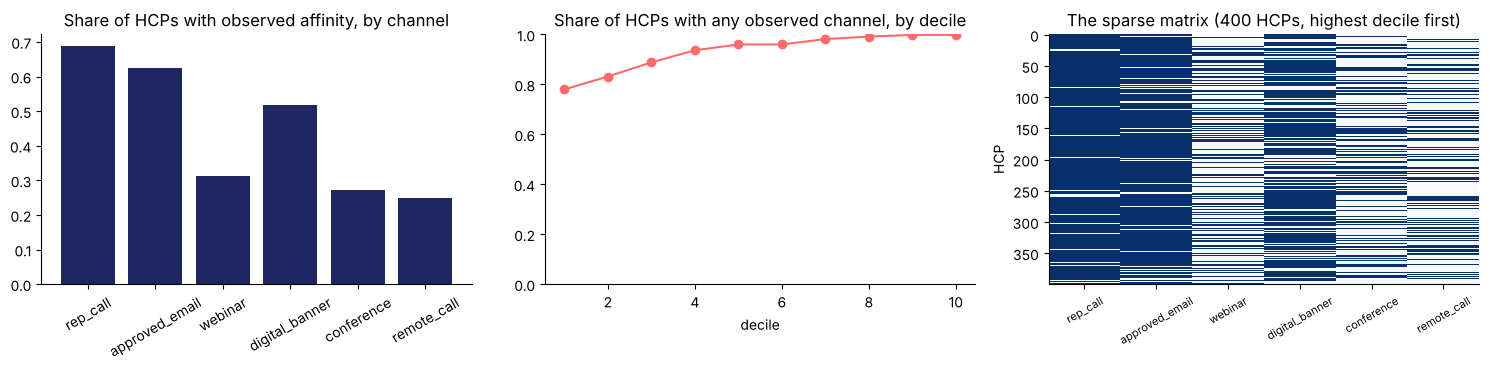

In [4]:
aff_obs = pd.read_csv(DATA / "glucoren_hcp_channel_affinity.csv")
CH = ["rep_call", "approved_email", "webinar", "digital_banner", "conference", "remote_call"]
hcps = segs.hcp_id.to_numpy(); hidx = {h: i for i, h in enumerate(hcps)}; cidx = {c: j for j, c in enumerate(CH)}
A = np.full((len(hcps), 6), np.nan)
for h, c, v in zip(aff_obs.hcp_id, aff_obs.channel, aff_obs.affinity): A[hidx[h], cidx[c]] = v
obs = ~np.isnan(A)
print(f"observed cells: {obs.mean():.1%} of {A.size:,} | HCPs with no observed channel: {(~obs.any(1)).sum():,} | survey HCPs: {aff_obs[aff_obs.source=='survey'].hcp_id.nunique()}")
cov = pd.DataFrame({"coverage": obs.mean(0)}, index=CH); cov["mean affinity (observed)"] = np.nanmean(A, 0)
print(cov.round(3).T)
seg_arr = segs.segment.to_numpy(); dec_arr = segs.decile.to_numpy()
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].bar(CH, obs.mean(0), color=NAVY); ax[0].set_title("Share of HCPs with observed affinity, by channel"); ax[0].tick_params(axis="x", rotation=30)
cd = pd.Series(obs.any(1)).groupby(dec_arr).mean(); ax[1].plot(cd.index, cd.values, "o-", color=CORAL); ax[1].set_ylim(0, 1); ax[1].set_title("Share of HCPs with any observed channel, by decile"); ax[1].set_xlabel("decile")
order = np.argsort(-dec_arr)[:400]; ax[2].imshow(obs[order].astype(int), aspect="auto", cmap="Blues", interpolation="nearest"); ax[2].set_title("The sparse matrix (400 HCPs, highest decile first)"); ax[2].set_xticks(range(6)); ax[2].set_xticklabels(CH, rotation=30, fontsize=8); ax[2].set_ylabel("HCP")
show("affinity_sparse")

### 4a. Hold-out design and the four estimators

In [5]:
rng_cf = np.random.default_rng(RNG)
cold = rng_cf.random(len(hcps)) < 0.10                               # cold-start HCPs: hide everything
cell_mask = (rng_cf.random(A.shape) < 0.20) & obs & ~cold[:, None]   # random held-out cells among the rest
train = obs & ~cell_mask & ~cold[:, None]
test_cells = cell_mask; test_cold = obs & cold[:, None]
Atr = np.where(train, A, np.nan)
print(f"train cells {train.sum():,} | held-out cells {test_cells.sum():,} | cold-start cells {test_cold.sum():,} ({cold.sum()} HCPs)")

# 1. segment x channel mean (the micro-segmentation prior)
seg_mean = pd.DataFrame(Atr, columns=CH).groupby(seg_arr).mean()
P_seg = seg_mean.loc[seg_arr].to_numpy()

# 2. kNN on Week 4 features (content-based): cosine similarity, weighted mean of neighbours' observed values
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
feat = segs.set_index("hcp_id")[["decile", "baseline_nbrx_wk", "glucoren_reject_rate", "email_consent", "segment"]].join(master.set_index("hcp_id")[["specialty", "practice_setting", "pct_medicare", "mean_patient_age"]]).loc[hcps]
F = pd.get_dummies(feat, columns=["segment", "specialty", "practice_setting"]).astype(float)
Fz = StandardScaler().fit_transform(F)
nn = NearestNeighbors(n_neighbors=51, metric="cosine").fit(Fz); dist, nbr = nn.kneighbors(Fz)
P_knn = np.full(A.shape, np.nan)
for j in range(6):
    col = Atr[:, j]
    for i in range(len(hcps)):
        ids = nbr[i, 1:]; vals = col[ids]; w = 1 - dist[i, 1:]; m = ~np.isnan(vals)
        P_knn[i, j] = np.average(vals[m], weights=w[m] + 1e-6) if m.sum() >= 3 else P_seg[i, j]

# 3. matrix factorization (collaborative filtering): factorize the RESIDUAL from the segment x channel prior,
#    r_ij = a_ij - prior_ij ~ b_i + u_i . v_j, by alternating ridge least squares (Koren-style biases + factors)
def als(M, prior, k=2, lam=2.0, iters=30, seed=RNG):
    r = np.random.default_rng(seed); n, m = M.shape; W = ~np.isnan(M)
    R = np.where(W, M - prior, 0.0)
    b = np.zeros(n); Uf = r.normal(0, 0.05, (n, k)); Vf = r.normal(0, 0.3, (m, k))
    for _ in range(iters):
        for i in range(n):                       # HCP side: bias + factors in one ridge solve (shrinks hard when the HCP has 1-2 cells)
            js = np.where(W[i])[0]
            if len(js) == 0: continue
            X = np.hstack([np.ones((len(js), 1)), Vf[js]]); y = R[i, js]
            beta = np.linalg.solve(X.T @ X + lam * np.eye(k + 1), X.T @ y); b[i] = beta[0]; Uf[i] = beta[1:]
        for j in range(m):                       # channel side (thousands of rows each: barely regularized)
            is_ = np.where(W[:, j])[0]
            X = Uf[is_]; y = R[is_, j] - b[is_]
            Vf[j] = np.linalg.solve(X.T @ X + 0.1 * np.eye(k), X.T @ y)
    return np.clip(prior + b[:, None] + Uf @ Vf.T, 0.01, 0.99), Uf, Vf, b
P_mf, U_hat, V_hat, b_hat = als(Atr, P_seg)

# 4. hybrid: MF where the HCP has training history, else the segment prior
has_hist = train.any(1)
P_hyb = np.where(has_hist[:, None], P_mf, P_seg)

def rmse(P, M): return float(np.sqrt(np.nanmean((P[M] - A[M]) ** 2)))
dense = (train.sum(1) >= 3)[:, None] & test_cells          # held-out cells of HCPs with >= 3 training cells
res = pd.DataFrame({name: {"held-out cells (all warm HCPs)": rmse(P, test_cells), "held-out, HCPs with ≥ 3 known cells": rmse(P, dense), "cold-start HCPs": rmse(P, test_cold)} for name, P in [("segment × channel mean", P_seg), ("kNN on Week 4 features", P_knn), ("matrix factorization (ALS, k=2)", P_mf), ("hybrid (MF + segment prior)", P_hyb)]}).T
print("RMSE on affinity (0-1 scale) — lower is better:"); print(res.round(4))
print(f"\ntraining cells per warm HCP: mean {train.sum(1)[train.any(1)].mean():.2f}; share with ≥ 3: {(train.sum(1) >= 3).mean():.1%}")

train cells 11,491 | held-out cells 2,859 | cold-start cells 1,639 (630 HCPs)


RMSE on affinity (0-1 scale) — lower is better:
                                 held-out cells (all warm HCPs)  held-out, HCPs with ≥ 3 known cells  cold-start HCPs
segment × channel mean                                    0.184                                0.182            0.185
kNN on Week 4 features                                    0.188                                0.190            0.189
matrix factorization (ALS, k=2)                           0.161                                0.131            0.290
hybrid (MF + segment prior)                               0.146                                0.131            0.185

training cells per warm HCP: mean 2.41; share with ≥ 3: 31.9%


**Read the table.** The segment prior is a strong baseline — that is what a good micro-segmentation buys you. Collaborative filtering improves on it where the HCP has history, and the improvement grows with the number of known cells: two or three observed channels place the HCP on the latent dimensions (roughly people-vs-digital, promotional-vs-scientific) and the model transfers that to the channels never offered. On cold-start HCPs it has nothing to factorize and reverts to the prior. The hybrid is what ships: matrix factorization for the warm HCPs, segment features for the cold ones — the structure of every recommender you use. The kNN on Week 4 features adds little over the segment mean because the features *are* the segmentation.

vs. planted truth on the 67% of cells nobody observed:
                        all unobserved cells  corr with truth
segment × channel mean                 0.174            0.553
kNN                                    0.178            0.527
matrix factorization                   0.189            0.545
hybrid                                 0.153            0.684


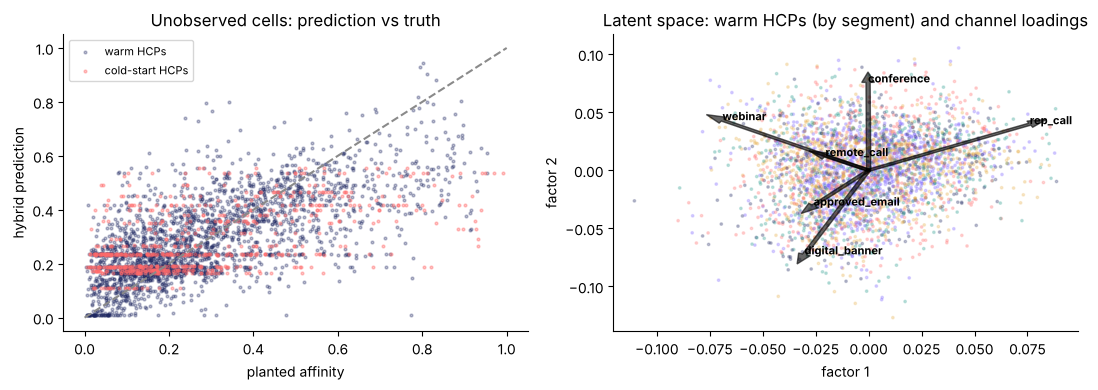

In [6]:
# ---- grade against the full matrix (instructor file)
tp = INSTR / "_INSTRUCTOR_affinity_truth.csv"
if tp.exists():
    T_aff = pd.read_csv(tp).set_index("hcp_id").loc[hcps, CH].to_numpy()
    unobs = ~obs
    g = pd.DataFrame({name: {"all unobserved cells": float(np.sqrt(np.mean((P[unobs] - T_aff[unobs]) ** 2))), "corr with truth": float(np.corrcoef(P[unobs], T_aff[unobs])[0, 1])} for name, P in [("segment × channel mean", P_seg), ("kNN", P_knn), ("matrix factorization", P_mf), ("hybrid", P_hyb)]}).T
    print("vs. planted truth on the 67% of cells nobody observed:"); print(g.round(3))
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].scatter(T_aff[unobs & ~cold[:, None]][::7], P_hyb[unobs & ~cold[:, None]][::7], s=4, alpha=0.3, color=NAVY, label="warm HCPs"); ax[0].scatter(T_aff[unobs & cold[:, None]][::3], P_hyb[unobs & cold[:, None]][::3], s=4, alpha=0.4, color=CORAL, label="cold-start HCPs")
    ax[0].plot([0, 1], [0, 1], "--", color=GREY); ax[0].set_xlabel("planted affinity"); ax[0].set_ylabel("hybrid prediction"); ax[0].set_title("Unobserved cells: prediction vs truth"); ax[0].legend(fontsize=8)
    warm = train.sum(1) >= 2
    ax[1].scatter(U_hat[warm, 0], U_hat[warm, 1], s=3, alpha=0.25, c=[{"Core": NAVY, "Movers": CORAL, "Access-constrained": TEAL, "Entrenched": GOLD, "Long tail": VIOLET}[s_] for s_ in seg_arr[warm]])
    sc_ = 0.6 * np.abs(U_hat[warm]).max() / np.abs(V_hat).max()
    for j, ch in enumerate(CH): ax[1].annotate(ch, (V_hat[j, 0] * sc_, V_hat[j, 1] * sc_), color="k", fontsize=8, weight="bold"); ax[1].arrow(0, 0, V_hat[j, 0] * sc_, V_hat[j, 1] * sc_, color="k", width=0.002, alpha=0.6)
    ax[1].set_title("Latent space: warm HCPs (by segment) and channel loadings"); ax[1].set_xlabel("factor 1"); ax[1].set_ylabel("factor 2")
    show("affinity_cf")
else:
    print("Instructor truth file not found — grading skipped (students' copy).")

### 4b. The full affinity matrix, and a check against revealed engagement
The output is one number per HCP per channel. Two uses downstream: the **segment × channel view** the brand team reads, and an **eligibility input** for the engine (§7: a channel with predicted affinity below 0.15 is not offered). The check: the touch log records whether each touch was engaged with — a predicted affinity should track the observed engagement rate per HCP on the three channels the engine uses.

predicted affinity by segment × channel:
                    rep_call  approved_email  webinar  digital_banner  conference  remote_call
Core                   0.520           0.290    0.450           0.300       0.550        0.380
Movers                 0.440           0.310    0.540           0.490       0.400        0.470
Access-constrained     0.400           0.240    0.350           0.280       0.330        0.360
Entrenched             0.350           0.110    0.280           0.170       0.420        0.190
Long tail              0.240           0.170    0.240           0.240       0.200        0.180


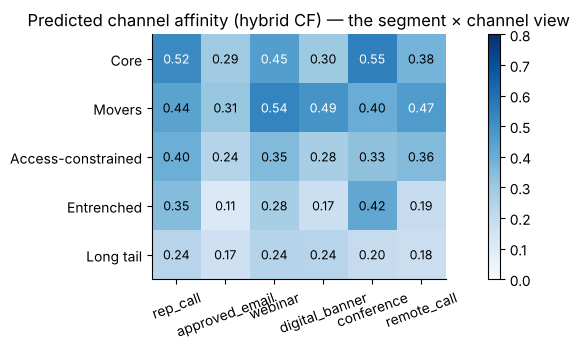


correlation of predicted affinity with observed engagement rate in the touch log (HCPs with ≥ 4 touches on the channel):
action
call      0.203
digital   0.326
email     0.289
dtype: float64

HCP × channel pairs below the 0.15 affinity floor: {'rep_call': 0.145, 'approved_email': 0.336, 'digital_banner': 0.253}


In [7]:
affinity_hat = pd.DataFrame(P_hyb, index=hcps, columns=CH)
aff_seg = affinity_hat.groupby(seg_arr).mean().reindex(SEG_ORDER)
print("predicted affinity by segment × channel:"); print(aff_seg.round(2))
fig, ax = plt.subplots(figsize=(9, 3.6))
im = ax.imshow(aff_seg.values, cmap="Blues", vmin=0, vmax=0.8); ax.set_xticks(range(6)); ax.set_xticklabels(CH, rotation=20); ax.set_yticks(range(5)); ax.set_yticklabels(aff_seg.index)
for i in range(5):
    for j in range(6): ax.text(j, i, f"{aff_seg.values[i, j]:.2f}", ha="center", va="center", color="white" if aff_seg.values[i, j] > 0.45 else "black", fontsize=9)
ax.set_title("Predicted channel affinity (hybrid CF) — the segment × channel view"); plt.colorbar(im, fraction=0.03)
show("affinity")
# revealed-engagement check on the three engine channels
MAP = {"call": "rep_call", "email": "approved_email", "digital": "digital_banner"}
eng = log[log.action != "none"].groupby(["hcp_id", "action"]).engaged.agg(["mean", "size"]).reset_index()
eng = eng[eng["size"] >= 4]
eng["pred_affinity"] = [affinity_hat.at[h, MAP[a]] for h, a in zip(eng.hcp_id, eng.action)]
print("\ncorrelation of predicted affinity with observed engagement rate in the touch log (HCPs with ≥ 4 touches on the channel):")
print(eng.groupby("action").apply(lambda d: np.corrcoef(d.pred_affinity, d["mean"])[0, 1]).round(3))
print(f"\nHCP × channel pairs below the 0.15 affinity floor: {(affinity_hat[list(MAP.values())] < 0.15).mean().round(3).to_dict()}")

**Affinity is not uplift.** Core has the highest affinity on almost every channel and — §5 — a modest incremental response. Affinity answers *how to reach*; uplift answers *whether it pays*. The engine needs both, and the segmentation sits under both.

## 5. Uplift modeling on the exploration arm
Now the model that matters. On randomized rows, for each action *a*, the conditional average treatment effect is
$\tau_a(x) = E[Y \mid X=x, A=a] - E[Y \mid X=x, A=\text{none}]$.

Three estimators, from simple to principled:
- **S-learner** — one model with the action as a feature; read the effect off by flipping the feature. Simple; shrinks the effect toward zero because the action is one feature among many.
- **T-learner** — one outcome model per arm; subtract. Honest, but each arm's model sees only its own rows, so differences are noisy where the rows are few.
- **X-learner** — T-learner, then a second stage that models the *imputed* individual effects and blends them with propensity weights. Designed for unequal arms; here the arms are equal, so it mostly regularizes.
- **Causal forest** (`econml`, optional) — honest trees on the effect directly. The course reading (Athey & Imbens) is the theory behind it.

The outcome is a count over two weeks with a long right tail, so the models predict the *mean*; we grade on deciles, not on R².

In [8]:
exp = log[log.arm == "explore"].copy()
U_FEATS = ["decile", "trailing_nbrx_wk", "calls_4w", "emails_4w", "digital_4w", "touches_4w", "weeks_since_call", "email_consent", "glucoren_reject_rate", "segment", "specialty", "last_action"]
def design(d): return pd.get_dummies(d[U_FEATS], columns=["segment", "specialty", "last_action"], drop_first=False).astype(float)
XU_all = design(log); XU = XU_all.loc[exp.index]
# split by HCP so the hold-out contains unseen prescribers
gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=RNG)
tr_idx, te_idx = next(gss.split(exp, groups=exp.hcp_id))
tr, te = exp.iloc[tr_idx], exp.iloc[te_idx]
def hgb(): return HGBR(max_iter=250, learning_rate=0.06, max_leaf_nodes=15, min_samples_leaf=40, l2_regularization=1.0, random_state=RNG)

# ---- T-learner: one model per action
T = {a: hgb().fit(XU.loc[tr.index][tr.action == a], tr.nbrx_2w[tr.action == a]) for a in ["none", "call", "email", "digital"]}
def tau_T(X):
    base = T["none"].predict(X); return pd.DataFrame({a: T[a].predict(X) - base for a in ["call", "email", "digital"]}, index=X.index)

# ---- S-learner: one model, action one-hot as features
def with_action(X, a):
    Z = X.copy()
    for b in ["call", "email", "digital"]: Z[f"A_{b}"] = float(a == b)
    return Z
XS = XU.loc[tr.index].assign(**{f"A_{b}": (tr.action == b).astype(float).values for b in ["call", "email", "digital"]})
S = hgb().fit(XS, tr.nbrx_2w)
def tau_S(X):
    base = S.predict(with_action(X, "none")); return pd.DataFrame({a: S.predict(with_action(X, a)) - base for a in ["call", "email", "digital"]}, index=X.index)

# ---- X-learner (two-stage; equal propensities so the blend weight is 0.5). Fit once, reuse everywhere below.
XL_models = {}
for a in ["call", "email", "digital"]:
    m1 = tr.action == a; m0 = tr.action == "none"
    D1 = tr.nbrx_2w[m1] - T["none"].predict(XU.loc[tr.index][m1])          # imputed effects on treated rows
    D0 = T[a].predict(XU.loc[tr.index][m0]) - tr.nbrx_2w[m0]              # imputed effects on control rows
    XL_models[a] = (hgb().fit(XU.loc[tr.index][m1], D1), hgb().fit(XU.loc[tr.index][m0], D0))
def tau_X(X):
    return pd.DataFrame({a: 0.5 * g1.predict(X) + 0.5 * g0.predict(X) for a, (g1, g0) in XL_models.items()}, index=X.index)

tauT_te, tauS_te, tauX_te = tau_T(XU.loc[te.index]), tau_S(XU.loc[te.index]), tau_X(XU.loc[te.index])
print("mean predicted uplift on hold-out HCP-weeks (NBRx per 2 weeks):")
print(pd.DataFrame({"S-learner": tauS_te.mean(), "T-learner": tauT_te.mean(), "X-learner": tauX_te.mean(), "randomized diff (§3)": honest["vs none"].drop("none")}).round(3))

mean predicted uplift on hold-out HCP-weeks (NBRx per 2 weeks):
         S-learner  T-learner  X-learner  randomized diff (§3)
call         0.076      0.127      0.130                 0.100
email        0.025      0.054      0.052                 0.104
digital      0.063      0.105      0.110                 0.093


### 5b. Evaluating an uplift model: uplift by predicted decile, and the Qini curve
There is no label for an individual's uplift, so uplift models are evaluated on *groups*: sort the hold-out HCP-weeks by predicted uplift, cut into deciles, and inside each decile compare the randomized treated and control outcomes. A good model gives a steep, monotone curve. The **Qini curve** cumulates incremental outcomes along the ranking; its area over the random diagonal (the Qini coefficient) is the one-number summary.

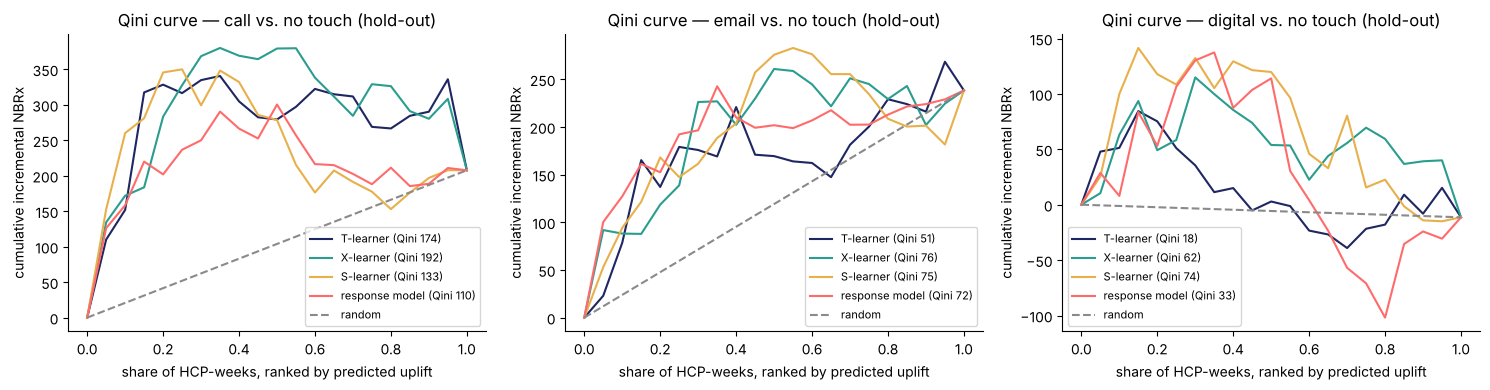

Qini coefficient (area above random, hold-out):
         S-learner  T-learner  X-learner  response model
call       133.000    174.000    192.000         110.000
digital     74.000     18.000     62.000          33.000
email       75.000     51.000     76.000          72.000

uplift by predicted decile (T-learner, call vs. none):
        n_t  n_c  observed_uplift  predicted
decile                                      
1       280  306           -0.188     -0.591
2       282  292            0.075     -0.120
3       304  286           -0.083     -0.045
4       313  298            0.011     -0.010
5       286  317            0.051      0.016
6       316  275            0.150      0.045
7       275  297           -0.076      0.087
8       295  282            0.144      0.180
9       273  309            0.600      0.438
10      282  303            0.516      1.270

uplift by predicted decile (RESPONSE model score, call vs. none) — the trap, quantified:
decile             1     2      3     

In [9]:
def uplift_by_decile(d, score, action, q=10):
    d = d.assign(score=score.values, dec=pd.qcut(score.rank(method="first"), q, labels=False) + 1)
    rows = []
    for k, g in d.groupby("dec"):
        t, c = g[g.action == action].nbrx_2w, g[g.action == "none"].nbrx_2w
        rows.append(dict(decile=k, n_t=len(t), n_c=len(c), observed_uplift=t.mean() - c.mean(), predicted=g.score.mean()))
    return pd.DataFrame(rows).set_index("decile")
def qini(d, score, action, steps=20):
    d = d[d.action.isin([action, "none"])].assign(score=score.values[d.action.isin([action, "none"]).values]).sort_values("score", ascending=False)
    n = len(d); xs, ys = [0], [0]
    for f in np.linspace(0.05, 1, steps):
        top = d.iloc[: int(f * n)]; t, c = top[top.action == action], top[top.action == "none"]
        if len(t) == 0 or len(c) == 0: continue
        ys.append((t.nbrx_2w.mean() - c.nbrx_2w.mean()) * len(t)); xs.append(f)
    xs, ys = np.array(xs), np.array(ys); area = np.trapezoid(ys, xs) - 0.5 * ys[-1]   # area above the random line
    return xs, ys, area
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
Q = {}
for ax, a in zip(axes, ["call", "email", "digital"]):
    sub = te[te.action.isin([a, "none"])]
    for name, tau, col in [("T-learner", tauT_te, NAVY), ("X-learner", tauX_te, TEAL), ("S-learner", tauS_te, GOLD), ("response model", te[["resp_score"]].rename(columns={"resp_score": a}), CORAL)]:
        xs, ys, area = qini(te, tau[a], a); Q[(a, name)] = area
        ax.plot(xs, ys, "-", color=col, label=f"{name} (Qini {area:.0f})")
    ax.plot([0, 1], [0, ys[-1]], "--", color=GREY, label="random"); ax.set_title(f"Qini curve — {a} vs. no touch (hold-out)"); ax.set_xlabel("share of HCP-weeks, ranked by predicted uplift"); ax.set_ylabel("cumulative incremental NBRx"); ax.legend(fontsize=8)
show("qini")
print("Qini coefficient (area above random, hold-out):"); print(pd.Series(Q).unstack().round(0))
print("\nuplift by predicted decile (T-learner, call vs. none):"); print(uplift_by_decile(te, tauT_te["call"], "call").round(3))
print("\nuplift by predicted decile (RESPONSE model score, call vs. none) — the trap, quantified:")
print(uplift_by_decile(te, te.resp_score, "call").round(3)[["observed_uplift"]].T)

**Read the Qini table.** For the rep call, every uplift learner beats ranking by *predicted response* (the §3 model), and the X-learner beats them all. The response model is not useless — on this data the heaviest prescribers also carry a lot of absolute uplift — but it ranks Core ahead of Movers for the call, and that is where the money leaks (§7). For the email the picture is different: the T-learner's two separate models are too noisy to find a small effect, and the X-learner's second stage — which models the *effect* directly and blends two estimates — roughly doubles the Qini. That is the X-learner earning its keep, and it is why it becomes the production model from §7 on. On a real log, where the control arm is 90% of rows, the gap is larger still.

hold-out HCP-weeks — correlation of X-learner uplift with the planted uplift of the same action in the same state:
{'call': np.float64(0.59), 'email': np.float64(0.39), 'digital': np.float64(0.555)}

by segment — mean predicted vs planted incremental NBRx per 2 weeks (hold-out HCP-weeks):
                    call: model  call: truth  email: model  email: truth  digital: model  digital: truth
segment                                                                                                 
Core                      0.440        0.159         0.341         0.153           0.314           0.108
Movers                    0.451        0.570         0.075         0.261           0.415           0.398
Access-constrained        0.050        0.038         0.070         0.136           0.062           0.055
Entrenched               -0.047       -0.049        -0.053        -0.035          -0.034          -0.054
Long tail                 0.041        0.037         0.021         0.011        

model best    call  digital  email
planted best                      
call         0.440    0.320  0.230
digital      0.240    0.500  0.260
email        0.340    0.340  0.320


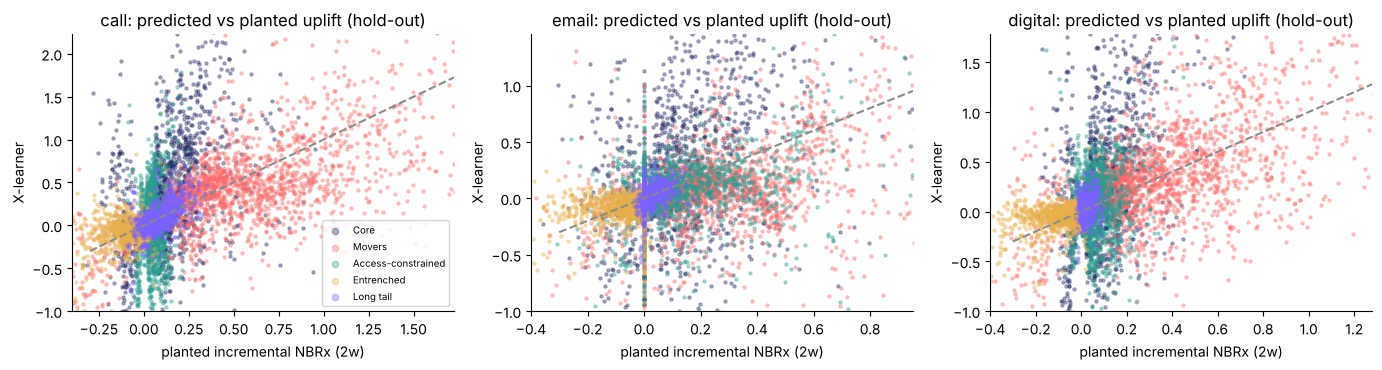

In [10]:
# ---- grade against the planted truth (instructor file): for every hold-out HCP-week, the generator's expected incremental NBRx of each action in THAT state
truth_path = INSTR / "_INSTRUCTOR_touch_log_truth.csv"
if truth_path.exists():
    rt = pd.read_csv(truth_path).set_index(["hcp_id", "week"])
    g = te.set_index(["hcp_id", "week"])[["segment"]].join(rt).reset_index(drop=True)
    g[["pred_call", "pred_email", "pred_digital"]] = tauX_te.values
    print("hold-out HCP-weeks — correlation of X-learner uplift with the planted uplift of the same action in the same state:")
    print({a: round(np.corrcoef(g[f"pred_{a}"], g[f"true_inc_nbrx_{a}"])[0, 1], 3) for a in ["call", "email", "digital"]})
    comp = g.groupby("segment")[["pred_call", "true_inc_nbrx_call", "pred_email", "true_inc_nbrx_email", "pred_digital", "true_inc_nbrx_digital"]].mean().reindex(SEG_ORDER)
    comp.columns = ["call: model", "call: truth", "email: model", "email: truth", "digital: model", "digital: truth"]
    print("\nby segment — mean predicted vs planted incremental NBRx per 2 weeks (hold-out HCP-weeks):"); print(comp.round(3))
    # does the model rank the right ACTION for each HCP-week? (ignoring cost)
    best_true = g[["true_inc_nbrx_call", "true_inc_nbrx_email", "true_inc_nbrx_digital"]].idxmax(axis=1).str.replace("true_inc_nbrx_", "")
    best_pred = g[["pred_call", "pred_email", "pred_digital"]].idxmax(axis=1).str.replace("pred_", "")
    print(f"\nshare of hold-out HCP-weeks where the model's best channel is the planted best channel: {(best_true == best_pred).mean():.1%} (chance = 33%)")
    print(pd.crosstab(best_true.rename("planted best"), best_pred.rename("model best"), normalize="index").round(2))
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
    for a_, a in zip(ax, ["call", "email", "digital"]):
        for s, col in zip(SEG_ORDER, [NAVY, CORAL, TEAL, GOLD, VIOLET]):
            m = g.segment == s; a_.scatter(g.loc[m, f"true_inc_nbrx_{a}"], g.loc[m, f"pred_{a}"], s=5, alpha=0.35, color=col, label=s)
        lim = g[f"true_inc_nbrx_{a}"].quantile(0.995); a_.plot([-0.3, lim], [-0.3, lim], "--", color=GREY); a_.set_xlim(-0.4, lim); a_.set_ylim(-1, lim + 0.5)
        a_.set_title(f"{a}: predicted vs planted uplift (hold-out)"); a_.set_xlabel("planted incremental NBRx (2w)"); a_.set_ylabel("X-learner")
    ax[0].legend(fontsize=7, markerscale=2)
    show("grade")
else:
    print("Instructor truth file not found — grading skipped (students' copy).")

**What the grade says.** The model recovers the *ordering* that matters: Movers first for the call and the digital placement, Entrenched negative everywhere (the sleeping dogs), Long tail near zero. It over-estimates the Core segment's uplift (sure things with a big baseline look incremental to a count model) and is weakest at the *within-HCP channel choice* — barely better than chance at naming the single best channel for a given HCP-week. That is the honest state of the art with 26 weeks of a 25% exploration arm (≈ 6 randomized weeks per HCP). An NBA engine is a *segment-and-context* machine with individual refinements, not an oracle for each prescriber — which is why the suppression rules and the segment priors in §6–7 matter as much as the model.

## 6. Saturation, frequency caps, and channel substitution
IQVIA's channel research has long reported that in the most-promoted markets HCPs "would prefer less communication via digital channels" and that digital's early success "resulted in overkill and saturation" (2018), and tracks "digital fatigue" (2023). The uplift above is an average over states. The Omnichannel Lead's second question is about the *marginal* touch: is the third call in a month worth what the first was? Three things to estimate on the exploration arm, each with the HCP's own baseline as the offset (a Poisson regression with `log(2 × trailing NBRx)` as offset):
1. **Fatigue** — lift of a touch by the number of touches already delivered in the trailing 4 weeks.
2. **Sleeping dogs** — the same curve for the Entrenched segment.
3. **Substitution** — an email the week after a call vs. an email after a quiet week.

lift of a touch (any channel) by touches already in the trailing 4 weeks — all segments except Entrenched:
                    n  lift_pct      lo     hi
touches_already                               
0                3484    27.200  18.200 37.000
1                6103    18.100  12.300 24.300
2                6834    11.200   6.700 15.800
3                4763     7.500   3.200 12.100
4                1548    -5.000 -10.500  0.800

Entrenched only:
                    n  lift_pct      lo      hi
touches_already                                
0                 754    -2.900 -23.600  23.400
1                1414   -29.800 -40.800 -16.800
2                1962   -22.200 -32.600 -10.100
3                1733   -14.700 -27.800   0.600
4                 632   -21.600 -38.800   0.300


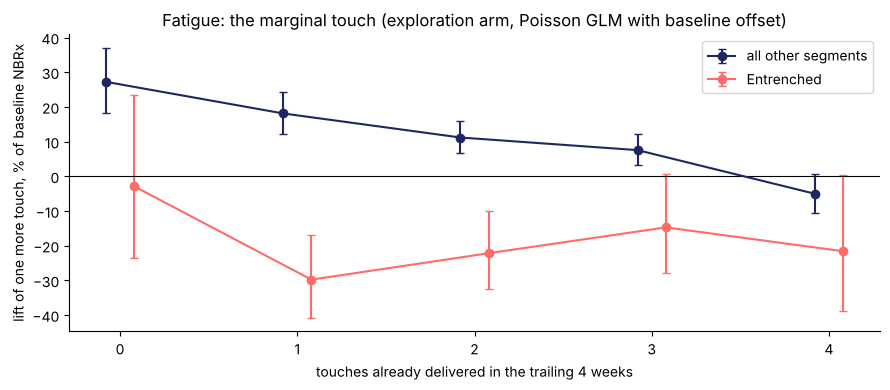


email lift after a quiet week: +10.1%   |   email lift the week after a rep call: +1.6%  (interaction p = 0.015)

emails by consent status:
                   n  complaints  nbrx
email_consent                         
0               2450         135 0.631
1              26846           0 1.407


In [11]:
e = exp.copy(); e["touch"] = (e.action != "none").astype(int); e["t4"] = e.touches_4w.clip(upper=4).astype(str); e["off"] = np.log(2 * e.trailing_nbrx_wk)
def fatigue_curve(d):
    m = smf.glm("nbrx_2w ~ C(t4) + touch:C(t4)", data=d, family=sm.families.Poisson(), offset=d["off"]).fit()
    rows = []
    for k in sorted(d.t4.unique()):
        name = f"touch:C(t4)[{k}]"; b, se = m.params[name], m.bse[name]
        rows.append(dict(touches_already=int(k), n=int(((d.t4 == k) & (d.touch == 1)).sum()), lift_pct=100 * (np.exp(b) - 1), lo=100 * (np.exp(b - 1.96 * se) - 1), hi=100 * (np.exp(b + 1.96 * se) - 1)))
    return pd.DataFrame(rows).set_index("touches_already")
fc_all = fatigue_curve(e[e.segment != "Entrenched"]); fc_ent = fatigue_curve(e[e.segment == "Entrenched"])
print("lift of a touch (any channel) by touches already in the trailing 4 weeks — all segments except Entrenched:"); print(fc_all.round(1))
print("\nEntrenched only:"); print(fc_ent.round(1))
fig, ax = plt.subplots(figsize=(9, 4))
for fc, col, lab in [(fc_all, NAVY, "all other segments"), (fc_ent, CORAL, "Entrenched")]:
    ax.errorbar(fc.index + (0.08 if col == CORAL else -0.08), fc.lift_pct, yerr=[fc.lift_pct - fc.lo, fc.hi - fc.lift_pct], fmt="o-", color=col, capsize=3, label=lab)
ax.axhline(0, color="k", lw=0.8); ax.set_xlabel("touches already delivered in the trailing 4 weeks"); ax.set_ylabel("lift of one more touch, % of baseline NBRx"); ax.set_title("Fatigue: the marginal touch (exploration arm, Poisson GLM with baseline offset)"); ax.legend()
show("fatigue")
# substitution: the email after a call
em = e[e.action.isin(["email", "none"])].copy(); em["email"] = (em.action == "email").astype(int); em["after_call"] = (em.last_action == "call").astype(int)
m = smf.glm("nbrx_2w ~ C(t4) + after_call + email + email:after_call", data=em[em.email_consent == 1], family=sm.families.Poisson(), offset=em.loc[em.email_consent == 1, "off"]).fit()
print(f"\nemail lift after a quiet week: {100*(np.exp(m.params['email'])-1):+.1f}%   |   email lift the week after a rep call: {100*(np.exp(m.params['email']+m.params['email:after_call'])-1):+.1f}%  (interaction p = {m.pvalues['email:after_call']:.3f})")
nc = log[(log.action == "email")].groupby("email_consent").agg(n=("nbrx_2w", "size"), complaints=("complaint", "sum"), nbrx=("nbrx_2w", "mean"))
print("\nemails by consent status:"); print(nc)

**The rules that fall out.** A touch on top of 0–1 others in the month is worth its full effect; on top of 2 it is worth about two-thirds; on top of 3 it is worth little; the 5th touch in four weeks *costs* NBRx. For Entrenched HCPs the curve bends a full step earlier — the second touch already halves, the third hurts. An email in the week after a call is worth less than half of a fresh one. An email to an HCP without consent does nothing and generates complaints.

So: **frequency cap 3 touches per 4 weeks (2 for Entrenched); no email within a week of a call; consent is a hard gate.** These are business rules — Axtria's orchestration framework names the ingredients as "AI/ML models, business rules, and governance" — and in §7 they sit *in front of* the model.

## 7. The NBA scoring layer
The NBA layer is three things in order: **eligibility** (business rules — hard constraints, now including the affinity floor from §4), **scoring** (expected incremental value of each eligible action), **selection** (argmax, with `none` always eligible). What the rep sees is a **suggestion** in CRM (Veeva CRM Suggestions; Axtria Triggers), and IQVIA reports tracking "acceptance of suggestions and follow through" — a program KPI, not an outcome. The score for action *a* on HCP *i* this week is

$\text{value}_{ia} = \hat\tau_a(x_i)\times\$1{,}200 - \text{cost}_a$

with $1,200 per incremental NBRx (a planning convention: ≈ 4.8 fills × $250 gross margin, from the Week 1 P&L via Week 3) and fully loaded costs of $180 per call, $2 per email, $6 per digital placement. The uplift model carries the context (touches in the trailing 4 weeks, last action, weeks since the last call), so fatigue and substitution are *inside* $\hat\tau$ — the caps are the belt to that pair of braces.

eligibility — share of HCPs blocked, by rule:
{'frequency cap': '41.7%', 'no consent': '25.0%', 'email after call': '17.8%', 'call recency': '31.8%', 'complaint': '0.6%', 'affinity floor (any channel)': '50.5%'}

NBA recommendation for next week, by segment (share of HCPs):
nba_action          none  call  email  digital
segment                                       
Core               0.650 0.055  0.137    0.158
Movers             0.391 0.171  0.043    0.394
Access-constrained 0.633 0.069  0.139    0.160
Entrenched         0.974 0.001  0.004    0.022
Long tail          0.459 0.023  0.194    0.324


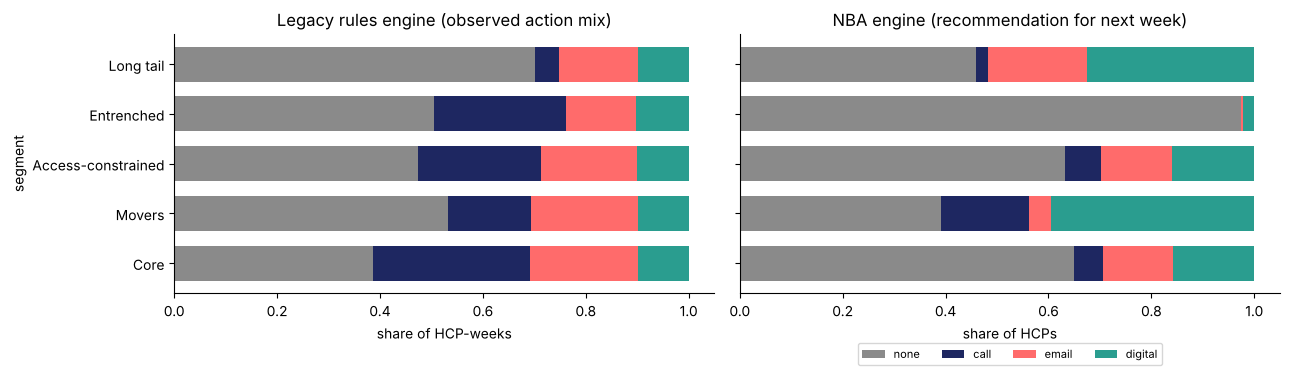


rep calls per week: legacy ≈ 955  →  NBA 297   | emails: legacy ≈ 1,003 → NBA 700
model-estimated incremental value next week: NBA $837,504  vs. legacy mix $169,014  (same model, legacy's actual actions last week)

top 10 HCPs by NBA value:
        segment  decile  touches_4w last_action nba_action  nba_value
hcp_id                                                               
H104780  Movers      10           2        call    digital  4,172.000
H101925  Movers       6           1        none    digital  4,114.000
H100981  Movers       8           0        none       call  3,957.000
H103523  Movers       8           1        call    digital  3,883.000
H104785  Movers       8           2        none    digital  3,668.000
H104412  Movers       9           2        none    digital  3,543.000
H105483  Movers       7           1        none    digital  3,420.000
H104847    Core      10           2        none    digital  3,386.000
H104007  Movers       8           2        none    digital

In [12]:
state = log[log.week == WEEKS[-1]].copy().set_index("hcp_id")      # the state of every HCP going into next week
XN = design(state.reset_index()).reindex(columns=XU.columns, fill_value=0.0); XN.index = state.index
tau = tau_X(XN)                     # the X-learner is the production model from here on (best or tied Qini on every channel)
value = tau * VALUE_PER_NBRX - pd.Series(COST).drop("none")
value["none"] = 0.0
# ---- suppression rules (eligibility)
elig = pd.DataFrame(True, index=state.index, columns=value.columns)
cap = np.where(state.segment == "Entrenched", 2, 3)
elig.loc[state.touches_4w >= cap, ["call", "email", "digital"]] = False                 # frequency cap
elig.loc[state.email_consent == 0, "email"] = False                                     # consent gate
elig.loc[state.last_action == "call", "email"] = False                                  # no email the week after a call
elig.loc[state.weeks_since_call < 2, "call"] = False                                    # call recency
recent_complaint = log[(log.week >= WEEKS[-8]) & (log.complaint == 1)].hcp_id.unique()
elig.loc[elig.index.isin(recent_complaint), "email"] = False                            # 8-week email suppression after a complaint
for a_, ch_ in MAP.items():                                                               # affinity floor (§4): do not offer a channel the HCP will not engage with
    elig.loc[affinity_hat.loc[elig.index, ch_].values < 0.15, a_] = False
nba = value.where(elig, -np.inf).idxmax(axis=1)
nba_value = value.where(elig, -np.inf).max(axis=1)
state["nba_action"] = nba; state["nba_value"] = nba_value
print("eligibility — share of HCPs blocked, by rule:")
print({"frequency cap": f"{(state.touches_4w >= cap).mean():.1%}", "no consent": f"{(state.email_consent == 0).mean():.1%}", "email after call": f"{(state.last_action == 'call').mean():.1%}", "call recency": f"{(state.weeks_since_call < 2).mean():.1%}", "complaint": f"{elig.index.isin(recent_complaint).mean():.1%}", "affinity floor (any channel)": f"{(affinity_hat.loc[elig.index, list(MAP.values())] < 0.15).any(axis=1).mean():.1%}"})
tab = pd.crosstab(state.segment, state.nba_action, normalize="index").reindex(SEG_ORDER)[["none", "call", "email", "digital"]]
print("\nNBA recommendation for next week, by segment (share of HCPs):"); print(tab.round(3))
# legacy engine for the same week, for comparison
leg_rules = log[log.arm == "legacy"].groupby("segment").action.value_counts(normalize=True).unstack().reindex(SEG_ORDER)[["none", "call", "email", "digital"]]
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
leg_rules.plot(kind="barh", stacked=True, ax=ax[0], color=[ACT_COLORS[a] for a in leg_rules.columns], width=0.7, legend=False); ax[0].set_title("Legacy rules engine (observed action mix)"); ax[0].set_xlabel("share of HCP-weeks")
tab.plot(kind="barh", stacked=True, ax=ax[1], color=[ACT_COLORS[a] for a in tab.columns], width=0.7); ax[1].set_title("NBA engine (recommendation for next week)"); ax[1].set_xlabel("share of HCPs"); ax[1].legend(ncol=4, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, -0.3))
show("nba_actions")
calls_leg = (log[log.arm == "legacy"].action == "call").mean() * 6000; calls_nba = (state.nba_action == "call").sum()
print(f"\nrep calls per week: legacy ≈ {calls_leg:,.0f}  →  NBA {calls_nba:,.0f}   | emails: legacy ≈ {(log[log.arm=='legacy'].action=='email').mean()*6000:,.0f} → NBA {(state.nba_action=='email').sum():,.0f}")
print(f"model-estimated incremental value next week: NBA ${state.nba_value.sum():,.0f}  vs. legacy mix ${(value.values * pd.get_dummies(state.action).reindex(columns=value.columns, fill_value=0).values).sum():,.0f}  (same model, legacy's actual actions last week)")
print("\ntop 10 HCPs by NBA value:"); print(state.sort_values("nba_value", ascending=False)[["segment", "decile", "touches_4w", "last_action", "nba_action", "nba_value"]].head(10).round(0))

**Read the two bar charts together.** The legacy engine's mix is the same for every segment except for call frequency (volume). The NBA engine moves calls from Core and Entrenched to Movers, moves Access-constrained HCPs to the (access-content) email, leaves most Entrenched and Long-tail HCPs alone this week, and spends fewer calls in total — with a higher model-estimated return. *Model-estimated* is the operative word; §8 is how you check that claim before anyone changes the call plan.

Two cautions. The 'none' share is the honest output of an engine whose cost line is real: a $180 call needs 0.15 incremental NBRx to break even. And the engine is only as good as the exploration arm that fed it — if the brand turns exploration off next quarter, the model cannot learn that Movers have become Core.

## 8. Offline policy evaluation — scoring a policy that was never run
Before an A/B test, estimate what the new policy would have earned *on the log you already have*. Three estimators, all of which need the logging propensity $p(a_t \mid x_t)$ for every row (which the legacy engine, written as probabilities, gives us):

- **IPS** (inverse propensity scoring): $\hat V(\pi)=\frac1n\sum_t \frac{\pi(a_t\mid x_t)}{p(a_t\mid x_t)}\,r_t$ — unbiased, high variance when $\pi$ picks actions the logger rarely took.
- **SNIPS** (self-normalized): divide by the sum of the weights instead of $n$ — biased slightly, far lower variance.
- **Doubly robust**: a reward model $\hat r(x,a)$ for every action plus IPS on the residual — unbiased if *either* the propensities or the reward model is right.

The reward is net value per HCP-week: $1{,}200\times$NBRx $-$ cost. We evaluate five policies, including the logging policy itself (a sanity check: IPS should return the observed mean).

observed mean reward in the log: $1,378 per HCP-week

                                            IPS     SNIPS        DR  IPS_se  eff_sample
policy                                                                                 
logging policy (legacy + 25% explore) 1,378.000 1,378.000 1,378.000   6.000 156,000.000
uniform random                        1,347.000 1,412.000 1,384.000   8.000  75,785.000
call deciles 9–10, email the rest     1,397.000 1,401.000 1,407.000  13.000  46,071.000
response-model policy                 1,403.000 1,411.000 1,415.000  14.000  30,379.000
uplift NBA + suppression              1,472.000 1,483.000 1,463.000  16.000  37,026.000


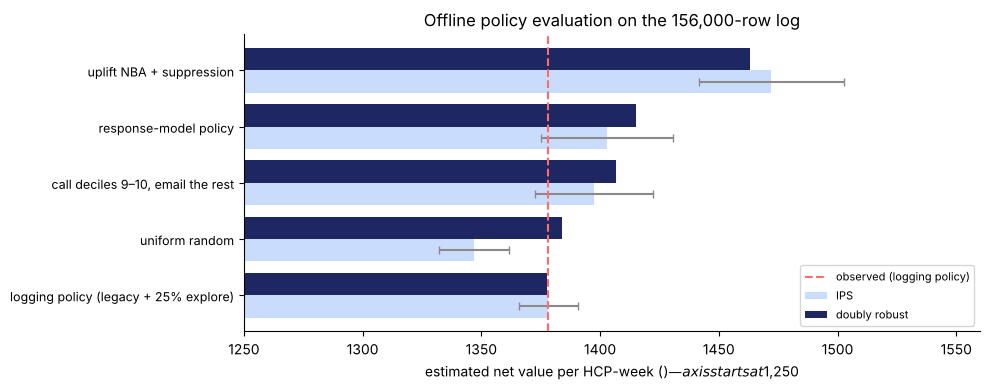

In [13]:
R = log.nbrx_2w * VALUE_PER_NBRX - log.action.map(COST)
A = ["none", "call", "email", "digital"]
XO = XU_all
# reward model for DR: one HGB per action on ALL rows (the legacy arm is fine here because the model conditions on x and a)
rm = {a: hgb().fit(XO[log.action == a], R[log.action == a]) for a in A}
rhat = pd.DataFrame({a: rm[a].predict(XO) for a in A}, index=log.index)
# target policies as probability tables over actions, per row. Deterministic policies get epsilon=0.05 of exploration so the ratio stays bounded.
def soft(choice, eps=0.05):
    P = pd.DataFrame(eps / 4, index=log.index, columns=A)
    for a in A: P.loc[choice == a, a] += 1 - eps
    return P
# NBA policy on every logged row: uplift model + suppression rules
tau_all = tau_X(XO); val_all = tau_all * VALUE_PER_NBRX - pd.Series(COST).drop("none"); val_all["none"] = 0.0
el = pd.DataFrame(True, index=log.index, columns=A)
el.loc[log.touches_4w >= np.where(log.segment == "Entrenched", 2, 3), ["call", "email", "digital"]] = False
el.loc[log.email_consent == 0, "email"] = False; el.loc[log.last_action == "call", "email"] = False; el.loc[log.weeks_since_call < 2, "call"] = False
for a_, ch_ in MAP.items(): el.loc[(affinity_hat.loc[log.hcp_id, ch_].values < 0.15), a_] = False
nba_choice = val_all.where(el, -np.inf).idxmax(axis=1)
resp_choice = pd.Series(np.where(log.resp_score >= log.resp_score.quantile(0.7), "call", np.where(log.email_consent == 1, "email", "digital")), index=log.index)
dec_choice = pd.Series(np.where(log.decile >= 9, "call", np.where(log.email_consent == 1, "email", "none")), index=log.index)
leg_P = pd.DataFrame(0.0, index=log.index, columns=A)
for a in A: leg_P.loc[log.action == a, a] = log.propensity[log.action == a]      # only the taken action's prob is logged; fill the rest from the rules
dec = log.decile.values; cons = log.email_consent.values
pc = np.select([dec >= 9, dec >= 7, dec >= 4], [0.38, 0.24, 0.10], 0.02); pe = np.where(cons == 1, 0.22, 0.0); pdg = np.full(len(log), 0.10)
leg_P = pd.DataFrame({"none": 1 - pc - pe - pdg, "call": pc, "email": pe, "digital": pdg}, index=log.index)
leg_P[log.arm == "explore"] = 0.25
policies = {"logging policy (legacy + 25% explore)": leg_P, "uniform random": pd.DataFrame(0.25, index=log.index, columns=A),
            "call deciles 9–10, email the rest": soft(dec_choice), "response-model policy": soft(resp_choice), "uplift NBA + suppression": soft(nba_choice)}
p_log = log.propensity.values; r = R.values; a_idx = log.action.map({a: i for i, a in enumerate(A)}).values
rows = []
for name, P in policies.items():
    pi_taken = P.values[np.arange(len(log)), a_idx]; w = np.clip(pi_taken / p_log, 0, 20)
    ips = np.mean(w * r); snips = np.sum(w * r) / np.sum(w)
    dm = (P.values * rhat.values).sum(1); dr = np.mean(dm + w * (r - rhat.values[np.arange(len(log)), a_idx]))
    se = np.std(w * r) / np.sqrt(len(r))
    rows.append(dict(policy=name, IPS=ips, SNIPS=snips, DR=dr, IPS_se=se, eff_sample=np.sum(w) ** 2 / np.sum(w ** 2)))
ope = pd.DataFrame(rows).set_index("policy")
print(f"observed mean reward in the log: ${r.mean():,.0f} per HCP-week\n"); print(ope.round(0))
fig, ax = plt.subplots(figsize=(10, 4))
y = np.arange(len(ope)); ax.barh(y - 0.2, ope.IPS, 0.4, color=ICE, label="IPS"); ax.barh(y + 0.2, ope.DR, 0.4, color=NAVY, label="doubly robust")
ax.errorbar(ope.IPS, y - 0.2, xerr=1.96 * ope.IPS_se, fmt="none", ecolor=GREY, capsize=3)
ax.set_yticks(y); ax.set_yticklabels(ope.index, fontsize=9); ax.axvline(r.mean(), color=CORAL, ls="--", label="observed (logging policy)"); ax.set_xlim(1250, 1560); ax.set_xlabel("estimated net value per HCP-week ($) — axis starts at $1,250"); ax.set_title("Offline policy evaluation on the 156,000-row log"); ax.legend(fontsize=8, loc="lower right")
show("ope")

**How to read it.** The logging policy evaluates to the observed mean (the sanity check passes). The *response-model policy* is barely above the status quo — it moves the $180 calls from Entrenched to Core, which is an improvement, and then spends them on sure things. The uplift NBA policy is estimated well above both, by a margin whose confidence interval you should quote, not its point estimate (IPS ± 2 × standard error is on the chart). All three estimators agree, which is the reassurance to look for. The effective-sample-size column is the honest cost of OPE: a policy far from the logger is evaluated on a fraction of the rows, and the estimate is only as good as the overlap. This is why the exploration arm has to *stay on*: next quarter's OPE needs it.

## 9. A toy contextual bandit — learning the policy online
An uplift model + argmax is a one-shot policy. A **contextual bandit** keeps learning: each week it picks an action given the context, observes the reward, and updates. The tension is explore/exploit; the standard answers are ε-greedy (explore a fixed share) and Thompson sampling (sample from the posterior of each arm's value and act greedily on the sample — it explores *where it is uncertain*).

The simulator below is deliberately simple: the context is the Week 4 segment, the environment is **segment × action → expected net value** estimated by the uplift model in §5 (not read from the generator), rewards are noisy, and we run 2,000 HCPs for 52 weeks with the policy learning from scratch. The point is the shape of the regret curves, not the dollar figures.

the simulator's environment — expected net value per HCP-week ($):
                    none     call     email   digital
Core               0.000  832.000 1,644.000 1,405.000
Movers             0.000  329.000   724.000   542.000
Access-constrained 0.000  -14.000   -20.000   156.000
Entrenched         0.000 -241.000   -13.000  -268.000
Long tail          0.000 -157.000     6.000    10.000


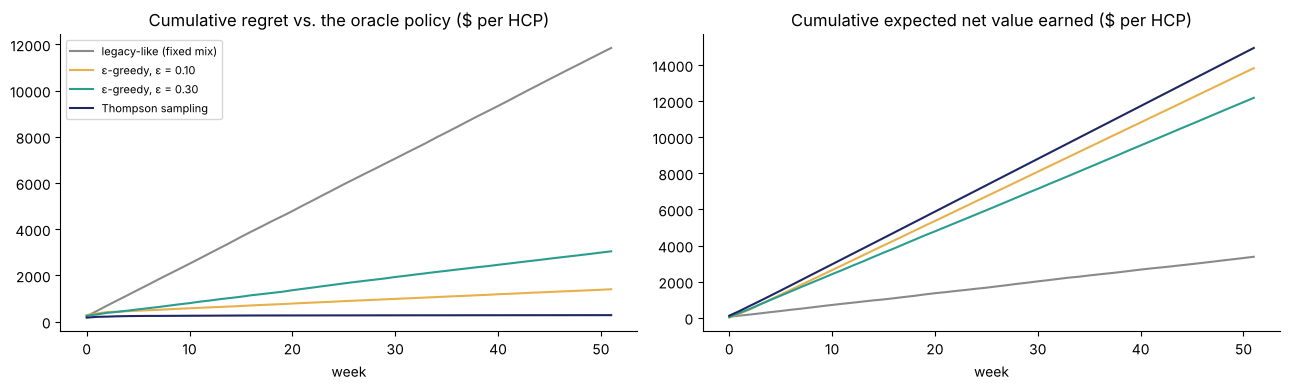

after 52 weeks — cumulative regret per HCP: {'legacy-like (fixed mix)': '$11,848', 'ε-greedy, ε = 0.10': '$1,403', 'ε-greedy, ε = 0.30': '$3,044', 'Thompson sampling': '$282'}
after 52 weeks — cumulative value per HCP: {'legacy-like (fixed mix)': '$3,382', 'ε-greedy, ε = 0.10': '$13,826', 'ε-greedy, ε = 0.30': '$12,185', 'Thompson sampling': '$14,947'}


In [14]:
rng = np.random.default_rng(RNG)
# environment: expected net value per (segment, action) for an HCP with one touch in the trailing 4 weeks — from the X-learner, not the generator
states = []
for s_ in SEG_ORDER:
    row = state[state.segment == s_].iloc[0].copy()
    row["touches_4w"] = 1; row["calls_4w"] = 0; row["emails_4w"] = 1; row["digital_4w"] = 0; row["last_action"] = "none"; row["weeks_since_call"] = 4
    states.append(row)
SD = pd.DataFrame(states).reset_index(drop=True)
XSD = design(SD).reindex(columns=XU.columns, fill_value=0.0)
ENV = (tau_X(XSD) * VALUE_PER_NBRX - pd.Series(COST).drop("none")); ENV["none"] = 0.0; ENV.index = SEG_ORDER; ENV = ENV[A]
print("the simulator's environment — expected net value per HCP-week ($):"); print(ENV.round(0))
NOISE = 900.0   # reward noise sd per HCP-week (≈ Poisson noise on 1-3 NBRx × $1,200)
SEG_P = segs.segment.value_counts(normalize=True).reindex(SEG_ORDER).values

def simulate(policy, n_hcp=2000, weeks=52, seed=0):
    rg = np.random.default_rng(seed)
    seg_i = rg.choice(5, n_hcp, p=SEG_P)
    n = np.zeros((5, 4)); tot = np.zeros((5, 4))                     # posterior sufficient statistics per (segment, action)
    mu_env = ENV.values; best = mu_env.max(1)
    regret = np.zeros(weeks); earned = np.zeros(weeks)
    for w in range(weeks):
        acts = policy(seg_i, n, tot, rg)
        mu = mu_env[seg_i, acts]; rew = mu + rg.normal(0, NOISE, n_hcp)
        np.add.at(n, (seg_i, acts), 1); np.add.at(tot, (seg_i, acts), rew)
        regret[w] = (best[seg_i] - mu).mean(); earned[w] = mu.mean()
    return regret.cumsum(), earned.cumsum()

def eps_greedy(eps):
    def pol(seg_i, n, tot, rg):
        mean = np.where(n > 0, tot / np.maximum(n, 1), 0.0); mean[n == 0] = 1e9     # try every arm once
        greedy = mean.argmax(1)[seg_i]
        return np.where(rg.random(len(seg_i)) < eps, rg.integers(0, 4, len(seg_i)), greedy)
    return pol
def thompson(seg_i, n, tot, rg):
    mean = np.where(n > 0, tot / np.maximum(n, 1), 0.0); sd = NOISE / np.sqrt(np.maximum(n, 1)); sd[n == 0] = 3 * NOISE
    sample = rg.normal(mean[seg_i], sd[seg_i]); return sample.argmax(1)
def legacy_like(seg_i, n, tot, rg): return rg.choice(4, len(seg_i), p=[0.57, 0.16, 0.17, 0.10])
results = {}
for name, pol in [("legacy-like (fixed mix)", legacy_like), ("ε-greedy, ε = 0.10", eps_greedy(0.10)), ("ε-greedy, ε = 0.30", eps_greedy(0.30)), ("Thompson sampling", thompson)]:
    results[name] = simulate(pol, seed=RNG)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for (name, (reg, earn)), col in zip(results.items(), [GREY, GOLD, TEAL, NAVY]):
    ax[0].plot(reg, color=col, label=name); ax[1].plot(earn, color=col, label=name)
ax[0].set_title("Cumulative regret vs. the oracle policy ($ per HCP)"); ax[0].set_xlabel("week"); ax[0].legend(fontsize=8)
ax[1].set_title("Cumulative expected net value earned ($ per HCP)"); ax[1].set_xlabel("week")
show("bandit")
print("after 52 weeks — cumulative regret per HCP:", {k: f"${v[0][-1]:,.0f}" for k, v in results.items()})
print("after 52 weeks — cumulative value per HCP:", {k: f"${v[1][-1]:,.0f}" for k, v in results.items()})

**What the curves say.** The fixed-mix engine never learns — its regret is a straight line. ε-greedy learns in a few weeks, then keeps paying the exploration tax forever: its regret keeps a constant slope, steeper for ε = 0.30 than for 0.10. Thompson sampling explores heavily early, where it is uncertain, and almost stops exploring once it is not — its regret curve flattens. In production the 'arms' are the actions scored by the uplift model (LinUCB or Thompson sampling on a linear reward model with the context as features), and the exploration share *is* the exploration arm from §1: the same thing, seen from the other side. The one thing the toy leaves out is the fatigue state — in production the context includes it, and the cap from §6 removes the over-touch actions from the arm set.

## 10. Patient predictive modeling — the patient-side NBA
The same engine, pointed at patients. The data is the Week 2/4 kind of asset: longitudinal **patient journeys** built from claims (Komodo Health distinguishes "closed" patients, whose full encounter history is captured, from "open" ones). The Week 4 patient file has a 12-month discontinuation flag; the question is *which patients on GLUCOREN are at risk of stopping, early enough to do something about it* — a patient-support-program (PSP) outreach, a copay-card reminder through the prescriber's office, an adherence nudge through the portal. Three disciplines:
1. **Only allowed features.** Journey and access features (PDC, refill gaps, copay, PSP, portal, prior lines, comorbidity count, ER visits, payer type) — no demographics beyond what the use case can justify, no free text, no sensitive attributes.
2. **Evaluate for the decision, not the leaderboard.** Precision in the top decile and calibration decide whether a nurse's call list is worth her day; AUC does not.
3. **Check it is fair before it is live.** Calibration *by payer type*: a model that over-flags Medicaid patients is a model that sends the outreach to the wrong people and the complaint to legal.

hold-out AUC 0.771 | average precision 0.373 | base rate 0.177

by predicted-risk decile (10 = highest):
          n  observed_rate  predicted  lift_vs_base  share_of_all_discontinuers
decile                                                                         
1       600          0.032      0.031         0.178                       0.018
2       600          0.045      0.044         0.254                       0.025
3       600          0.057      0.055         0.319                       0.032
4       600          0.058      0.065         0.329                       0.033
5       600          0.067      0.079         0.376                       0.038
6       600          0.120      0.118         0.676                       0.068
7       600          0.252      0.232         1.418                       0.142
8       600          0.352      0.326         1.981                       0.198
9       600          0.392      0.397         2.207                       0.221
10      600    

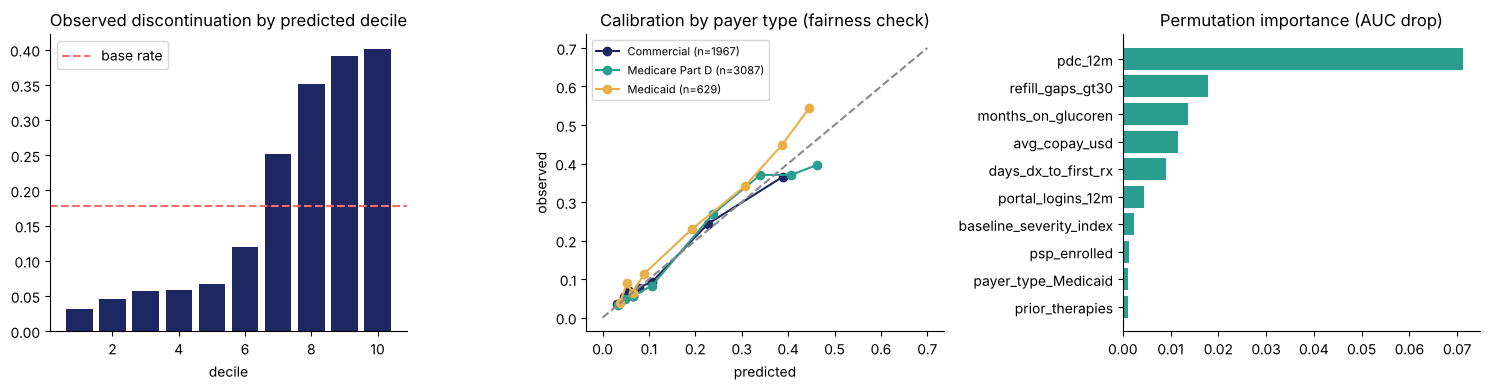


patient NBA for the top two risk deciles (hold-out):
PSP enrollment outreach (via prescriber office)    1081
copay-support reminder                               87
nurse call (PSP)                                     20
adherence nudge (portal / pharmacy)                  12
Name: count, dtype: int64

If the PSP nurse team can work 20% of patients: they reach 45% of the patients who will discontinue, at 40% precision (vs 18% at random).


In [15]:
P_FEATS = ["pdc_12m", "refill_gaps_gt30", "avg_copay_usd", "psp_enrolled", "portal_logins_12m", "prior_therapies", "comorbidity_count", "er_visits_12m", "months_on_glucoren", "days_dx_to_first_rx", "n_switches", "baseline_severity_index", "payer_type", "index_prescriber_specialty"]
XP = pd.get_dummies(patients[P_FEATS], drop_first=True); yP = patients.discontinued
Xtr, Xte, ytr, yte, ptr, pte = train_test_split(XP, yP, patients.payer_type, test_size=0.3, random_state=RNG, stratify=yP)
clf = HGBC(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, random_state=RNG).fit(Xtr, ytr)
p = clf.predict_proba(Xte)[:, 1]
print(f"hold-out AUC {roc_auc_score(yte, p):.3f} | average precision {average_precision_score(yte, p):.3f} | base rate {yte.mean():.3f}")
dec = pd.qcut(pd.Series(p).rank(method="first"), 10, labels=False) + 1
lift = pd.DataFrame({"decile": dec.values, "y": yte.values, "p": p}).groupby("decile").agg(n=("y", "size"), observed_rate=("y", "mean"), predicted=("p", "mean"))
lift["lift_vs_base"] = lift.observed_rate / yte.mean(); lift["share_of_all_discontinuers"] = lift.n * lift.observed_rate / (yte.sum())
print("\nby predicted-risk decile (10 = highest):"); print(lift.round(3))
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].bar(lift.index, lift.observed_rate, color=NAVY); ax[0].axhline(yte.mean(), color=CORAL, ls="--", label="base rate"); ax[0].set_title("Observed discontinuation by predicted decile"); ax[0].set_xlabel("decile"); ax[0].legend()
for pt, col in zip(["Commercial", "Medicare Part D", "Medicaid"], [NAVY, TEAL, GOLD]):
    m = (pte == pt).values
    if m.sum() > 200:
        fr, mp = calibration_curve(yte[m], p[m], n_bins=8, strategy="quantile"); ax[1].plot(mp, fr, "o-", color=col, label=f"{pt} (n={m.sum()})")
ax[1].plot([0, 0.7], [0, 0.7], "--", color=GREY); ax[1].set_title("Calibration by payer type (fairness check)"); ax[1].set_xlabel("predicted"); ax[1].set_ylabel("observed"); ax[1].legend(fontsize=8)
from sklearn.inspection import permutation_importance
pi = permutation_importance(clf, Xte, yte, n_repeats=5, random_state=RNG, scoring="roc_auc")
imp = pd.Series(pi.importances_mean, index=XP.columns).sort_values().tail(10)
ax[2].barh(imp.index, imp.values, color=TEAL); ax[2].set_title("Permutation importance (AUC drop)")
show("patient_risk")
# the patient NBA: who gets which outreach
te_p = patients.loc[Xte.index].assign(risk=p, dec=dec.values)
top = te_p[te_p.dec >= 9]
rule = np.select([(top.psp_enrolled == 0), (top.avg_copay_usd > 50), (top.portal_logins_12m == 0)], ["PSP enrollment outreach (via prescriber office)", "copay-support reminder", "adherence nudge (portal / pharmacy)"], "nurse call (PSP)")
print("\npatient NBA for the top two risk deciles (hold-out):"); print(pd.Series(rule).value_counts())
print(f"\nIf the PSP nurse team can work 20% of patients: they reach {lift.loc[9:, 'share_of_all_discontinuers'].sum():.0%} of the patients who will discontinue, at {lift.loc[9:, 'observed_rate'].mean():.0%} precision (vs {yte.mean():.0%} at random).")

**Governance, in one paragraph.** This model produces a *score about a person* and a *contact* that follows from it. Purpose limitation (the score exists to support adherence, not to deprioritize anyone), data minimization (the feature list above, nothing else), consent for the outreach channel, a fairness check by payer and by prescriber specialty, drift monitoring on the score distribution, and a human in the loop at the point of contact — the nurse decides, the model ranks. The reading pack (Part D) has IQVIA's description of the same controls for patient analytics at scale.

## 11. Orchestration — triggers, suppression rules, the CDP, and the measurement plan
What turns a model into a program. Four parts, and the model is the smallest of them:
- **Signals and triggers.** Events that *start* a decision: a Movers HCP's NBRx jumps (reinforce), an Access-constrained HCP's reject rate crosses 25% (switch to the access email), a Week 4 exit trigger fires (re-segment), a patient's refill gap passes 30 days (patient NBA). Weekly batch for the field; event-driven for digital.
- **Business rules (suppression rules).** Consent, frequency caps, recency, complaint holds, compliance holds (no promotional email to an HCP under a medical-information request), sample-eligibility. They run *before* scoring, and they are owned by compliance and the field, not by the data science team.
- **The CDP.** The customer data platform is the system that owns identity (one HCP across CRM, email platform, web, Rx data) and the consent record. If it does not exist, the NBA engine is a spreadsheet. IQVIA's phrase for this is the 'common data spine' (reading pack, Part C).
- **Measurement.** A standing 10% *global holdout* (HCPs who receive the legacy engine, or nothing), the exploration arm (randomized HCP-weeks inside the treated population), OPE every quarter on the log, and a quarterly A/B of engine versions. Report incremental NBRx and net value, never 'engagement' — ZS (2026) on why: pharma has relied on "activity and adoption metrics that capture results only after they occur". ZS and Axtria now describe the next step as **next best experience**: closed-loop learning in which "every interaction [is] a learning event", explainable suggestions, and human-in-the-loop controls.

In [16]:
rules = pd.DataFrame([
    ["Consent", "No approved email without opt-in; no digital retargeting without cookie consent", "Hard gate", "Compliance / Privacy"],
    ["Frequency cap", "≤ 3 touches per 4 weeks (≤ 2 for Entrenched)", "Hard gate", "Brand + Field"],
    ["Call recency", "No rep call within 2 weeks of the last call; field may override with a logged reason", "Soft gate", "Field"],
    ["Channel sequencing", "No email in the week after a call (substitution); email → digital allowed", "Soft gate", "Omnichannel"],
    ["Complaint hold", "8 weeks of email silence after a spam / unsubscribe complaint", "Hard gate", "Compliance"],
    ["Medical-information hold", "No promotional touch while an MI request is open", "Hard gate", "Medical"],
    ["Access trigger", "Reject rate > 25% → access/copay content replaces efficacy content", "Content rule", "Market Access"],
    ["Re-segmentation trigger", "Week 4 exit trigger fires → re-score segment before next decision", "Routing rule", "Analytics"],
    ["Global holdout", "10% of HCPs excluded from the engine for measurement", "Design", "Analytics"],
    ["Exploration arm", "20–25% of HCP-weeks randomized among eligible actions", "Design", "Analytics"]], columns=["rule", "definition", "type", "owner"])
print(rules.to_string(index=False))

                    rule                                                                           definition         type                owner
                 Consent      No approved email without opt-in; no digital retargeting without cookie consent    Hard gate Compliance / Privacy
           Frequency cap                                         ≤ 3 touches per 4 weeks (≤ 2 for Entrenched)    Hard gate        Brand + Field
            Call recency No rep call within 2 weeks of the last call; field may override with a logged reason    Soft gate                Field
      Channel sequencing            No email in the week after a call (substitution); email → digital allowed    Soft gate          Omnichannel
          Complaint hold                        8 weeks of email silence after a spam / unsubscribe complaint    Hard gate           Compliance
Medical-information hold                                     No promotional touch while an MI request is open    Hard gate              

## 12. Wrap-up — what to leave with
1. **NBA is a causal problem, not a prediction problem.** The target is the *difference* an action makes; a response model ranks the sure things.
2. **Randomize something, and keep randomizing.** The exploration arm is the data asset; the model is derived from it. Without it there is no uplift model, no OPE, and no learning next quarter.
3. **Three components, in order.** Segmentation says who; affinity (predicted by collaborative filtering where it is not observed) says how to reach them; uplift says whether it pays. Affinity ≠ uplift.
4. **The marginal touch has its own curve.** Fatigue, sleeping dogs, substitution and consent are rules — and they sit in front of the model.
5. **Score policies offline before you test them online**, and quote the interval.
6. **The patient side is the same engine with stricter governance** — purpose limitation, minimal features, fairness by payer, a human at the point of contact.

**Next week (Week 6, October 19):** forecasting — epidemiology-based patient flow, classical time series vs. foundation models. Homework 2 is released then.